# 04 · Kinetic energy (Appendix E, Table S20, `tab:ke_mae`)

Kinetic-energy error of each generated sample against the reference, per rollout step:
`ke_mae_tm` = |E_k(v_m) - E_k(u)|, averaged over the samples and divided by the
time-mean reference energy of the trajectory (`wavelet_flow_matching/analysis/physics.py`).

The paper table is built by `01_tables.ipynb` (`P.s20_ke_mae`); it is shown again at the end
of this notebook. The figure (error vs. lead time) is a diagnostic and is not in the paper.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

from wavelet_flow_matching.analysis import catalog as C, tables as T, paper_tables as P
from wavelet_flow_matching.analysis.physics import add_tm_metrics

T.STD_REL, T.TIE_MODE = 0.05, "unrounded"
plt.rcParams.update({"font.family": "serif", "font.size": 9, "axes.linewidth": 0.8})

## 1 · Load the per-seed physics rows (selected wavelets + generative baselines)

In [2]:
_, gdf = C.load(models=C.WFM_ALL + C.GEN_MODELS, verbose=True)
g = T.best_view(add_tm_metrics(gdf), keep=C.GEN_MODELS)

# per seed: mean over trajectories at each step; then mean and min/max over seeds
per_seed = g.groupby(["pde", "model", "seed", "step"])["ke_mae_tm"].mean().reset_index()
curve = per_seed.groupby(["pde", "model", "step"])["ke_mae_tm"].agg(["mean", "min", "max"]).reset_index()
curve.head()

loaded 796,977 rows from 102 files (676,713 per-field, 120,264 global)


,pde,model,step,mean,min,max
0,active_matter,FM_fourier,1,0.222165,0.221860,0.222548
1,active_matter,FM_fourier,2,0.241065,0.239840,0.242210
2,active_matter,FM_fourier,3,0.252383,0.251838,0.253315
3,active_matter,FM_fourier,4,0.271241,0.269840,0.272682
4,active_matter,FM_fourier,5,0.305642,0.304725,0.306171


## 2 · Error vs. lead time

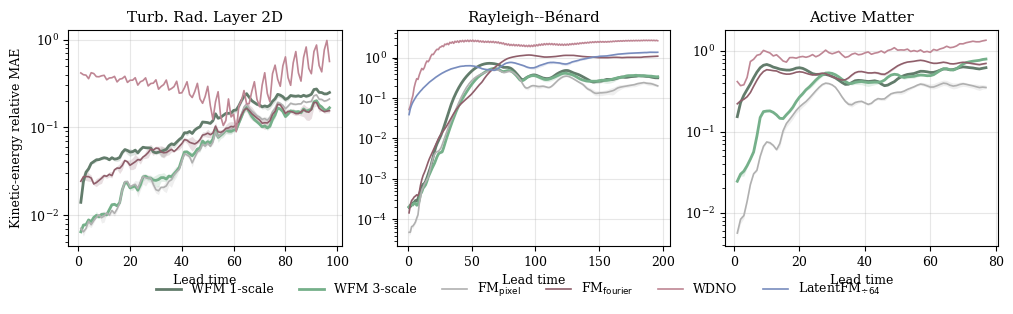

In [3]:
fig, axes = plt.subplots(1, len(C.PDES), figsize=(12, 2.8))
for ax, pde in zip(axes, C.PDES):
    for m in C.ROWS_BEST_GEN:
        d = curve[(curve.pde == pde) & (curve.model == m)]
        if d.empty:
            continue
        ax.plot(d.step, d["mean"], color=C.COLORS[m], lw=2.0 if m in C.BEST else 1.2, label=C.LABELS[m])
        ax.fill_between(d.step, d["min"], d["max"], color=C.COLORS[m], alpha=0.2, lw=0)
    ax.set_title(C.PDE_LABELS[pde].replace(r"\'{e}", "é"))
    ax.set_xlabel("Lead time")
    ax.set_yscale("log")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Kinetic-energy relative MAE")
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=len(labels), bbox_to_anchor=(0.5, -0.12), frameon=False)
fig.savefig(PROJECT_ROOT / "artifacts" / "figures" / "diag_ke_mae_lead_time.pdf", bbox_inches="tight")
plt.show()

## 3 · Paper table

In [4]:
P.s20_ke_mae(gdf, show_std=False)

  wrote S20_ke_mae


(                turbulent_radiative_layer_2D                      \
                                        01:32     33:64     65:97   
 WFM_1scale_best                     0.046715  0.113109  0.220656   
 WFM_3scale_best                     0.016979  0.067451  0.146609   
 FM_pixel                            0.016155  0.066876  0.176606   
 FM_fourier                          0.037222  0.082444  0.149646   
 WDNO                                0.355859  0.224912  0.456987   
 LatentFM                                 NaN       NaN       NaN   
 
                 rayleigh_benard                     active_matter            \
                           01:32     33:64    65:196         01:16     17:32   
 WFM_1scale_best        0.007229  0.409741  0.379066      0.501904  0.537694   
 WFM_3scale_best        0.002774  0.216703  0.347906      0.112457  0.391376   
 FM_pixel               0.003754  0.234893  0.251337      0.051137  0.287566   
 FM_fourier             0.006198  0.153251  1.